In [1]:
import os
from datetime import time

import geopandas as gpd
import pandas as pd
import gtfs_kit

In [2]:
DATAPATH = 'C:/Users/jmuir/source/urban-mobility-simulation/data/infrastructure'
GTFS_IN = os.path.join(DATAPATH, 'GTFS.zip')
TRANSIT_OUT = os.path.join(DATAPATH, 'transit_timetable.csv')
TRANSIT_SHAPES_OUT = os.path.join(DATAPATH, 'transit_shapes.csv')

SCHEMA = ['stop_id', 'stop_lat', 'stop_lon', 'departure_time', 'dep_next_day', 'shape_dist_traveled',
          'route_id', 'service_id', 'trip_id', 'trip_short_name', 'shape_id', 'direction_id', 'stop_sequence',
          'monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday']

WEEKDAYS = ['monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday']

# Bus 200 = 17350_700
# Bus 246 = 17362_700
# Bus M11 =

ROUTE = '17350_700' # which route to restrict to
WEEK = ['20210809', '20210810', '20210811', '20210812', '20210813', '20210814', '20210815'] # exemplary week for route timetable

In [3]:
# Load GTFS feed
gtfs = gtfs_kit.read_feed(GTFS_IN, 'm')

# ...and restrict to route
gtfs = gtfs.restrict_to_routes([ROUTE])

# ...then clean
gtfs = gtfs.clean()

# and add optional, hence non-existent (shame on you BVG) shape_dist_travelled fields for distance computations
gtfs = gtfs.append_dist_to_shapes()
gtfs = gtfs.append_dist_to_stop_times()

C:\Users\jmuir\miniconda3\envs\urban-mobility-simulation\lib\site-packages\gtfs_kit\cleaners.py:46: FutureWarning: The default value of regex will change from True to False in a future version.
  f[column] = f[column].str.strip().str.replace(r"\s+", "_")


In [4]:
# build route timetable
timetable = gtfs.build_route_timetable(ROUTE, WEEK)
timetable = timetable.merge(gtfs.stops, on='stop_id')
timetable = timetable.merge(gtfs.calendar, on='service_id')
timetable['route_id'] = ROUTE

# add next day flag on >24:00 and standardize time
timetable['dep_next_day'] = timetable['departure_time'] >= '24:00:00'

In [5]:
# There are some trips that have dep_next_day on all stops because they belong to a
# service that (usually ?) doesnt have trips on the following day
# We don't care about services and need to clean this up

def clean_next_day_dep(trip):
    if len(trip[~trip['dep_next_day']].index) == 0:
        # if all stops have departure_next_day, then remove that flag but shift the service days accordingly
        if len(trip[~((trip[WEEKDAYS] == 1).all(axis='columns'))].index) == 0:
            # nothing to shift, this service is in service each day
            trip.loc[:,'dep_next_day'] = False
        else:
            # this trip is not in service each day, so we gotta shift service days for those days
            # that have dep_next_day for all stops
            if (trip[WEEKDAYS].mean(axis='index') % 1 > 0).any():
                # if however any day is not always in service (1) or not in service (0)
                # it gets complicated
                raise NotImplementedError(f'we gotta work on trip {trip.at[trip.index[-1], "trip_id"]}')

            monday = trip['sunday'].to_numpy(copy=True) # overflow sunday (value copy) to monday,
            trip.loc[:,WEEKDAYS] = trip.loc[:,WEEKDAYS].shift(periods=1, axis='columns', fill_value=0)
            trip.loc[:,'monday'] = monday
            trip.loc[:,'dep_next_day'] = False
        return trip
    else:
        # not all stops have departure_next_day, so we leave everything as is
        return trip

timetable['hours'] = pd.to_numeric(timetable['departure_time'].str[:2], downcast='integer')
timetable['minutes'] = pd.to_numeric(timetable['departure_time'].str[3:5], downcast='integer')
timetable['seconds'] = pd.to_numeric(timetable['departure_time'].str[6:], downcast='integer')
timetable.loc[timetable['dep_next_day'], 'hours'] = timetable.loc[timetable['dep_next_day'], 'hours'] - 24
timetable['departure_time'] = timetable.apply(lambda x: time(x['hours'], x['minutes'], x['seconds']).strftime('%H:%M:%S'), axis=1)
timetable = timetable.groupby('trip_id').apply(clean_next_day_dep).reset_index(drop=True)

# clean up schema
# check if all attributes of SCHEMA are present in the feed, else create an artificial NaN column
for attr in SCHEMA:
    if attr not in list(timetable):
        timetable[attr] = pd.NA
        print('Attribute', attr,
              'was not found in the feed. Inserted empty column. This might lead to unexpected behaviour!')

droplist = list(set(timetable) ^ set(SCHEMA))  # xor operator with two sets yields the difference - then convert that to list
timetable.drop(droplist, inplace=True, axis=1)
# re-arrange columns
timetable = timetable[SCHEMA]

# and clean up duplicated again
timetable = timetable[~timetable.duplicated()]

# save both timetable and shapes
timetable.to_csv(TRANSIT_OUT, index=False)
gtfs.shapes.to_csv(TRANSIT_SHAPES_OUT, index=False)

In [6]:
gtfs.validate()

,type,message,table,rows
0,error,Invalid route_type; maybe has extra space char...,routes,[771]
1,warning,Unrecognized column platform_code,stops,[]
2,warning,Unrecognized column from_route_id,transfers,[]
3,warning,Unrecognized column to_route_id,transfers,[]
4,warning,Unrecognized column from_trip_id,transfers,[]
5,warning,Unrecognized column to_trip_id,transfers,[]


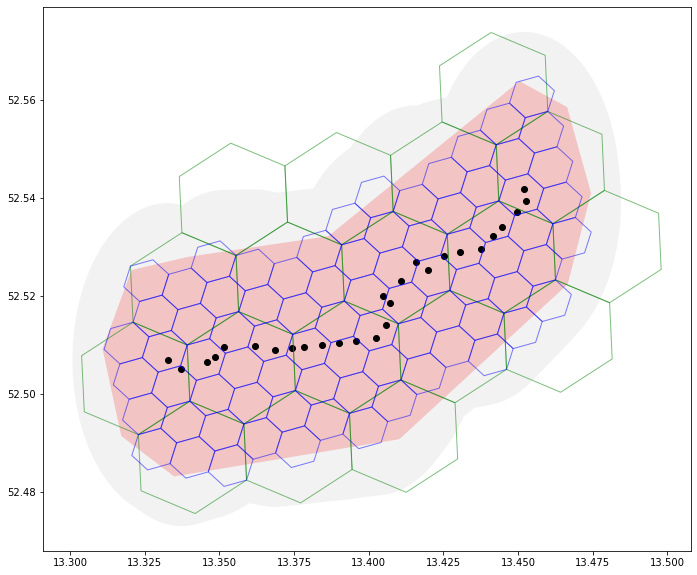

In [203]:
# now that we have the route, we need to build two things:
# 1. a demand modifier buffer around it to tune up demand generation around the route for dynamic transit
# 2. an action space that is also a buffer around it, but in higher resolution
# These two should be as similar as possible.

BUFFERSIZE = 0.022
# play around with this until the red area in the plot looks sufficiently polyfilled with green hexagon cells
# the same polyfill will happen in the simulation demand factory
SAFEBUFFER = 0.01
SIMPLIFY_RATIO = 0.006

import h3
import json
from matplotlib import pyplot as plt
from shapely.geometry.point import Point
from shapely.geometry.polygon import Polygon
from shapely.geometry.linestring import LineString

route_stops = timetable[~timetable.duplicated(subset=['stop_lat', 'stop_lon'])]
route_stops = route_stops[~route_stops.duplicated(subset=['stop_sequence'])]
stops_points = route_stops.sort_values('stop_sequence').apply(lambda x: Point(x['stop_lon'], x['stop_lat']), axis=1)
stops_gpd = gpd.GeoDataFrame.from_records([{'id': k, 'geometry': v} for k, v in enumerate(stops_points)])
stops_gpd.to_json(drop_id=True)

buffer = LineString(list(stops_points)).buffer(BUFFERSIZE)
safebuffer = gpd.GeoSeries(buffer.buffer(SAFEBUFFER))
simplified_buffer = gpd.GeoSeries(buffer).simplify(SIMPLIFY_RATIO)

fig, ax = plt.subplots(figsize=(12,10))
simplified_buffer.plot(ax=ax, color='red', alpha=.2)
safebuffer.plot(ax=ax, color='grey', alpha=.1)
stops_gpd.plot(ax=ax, color='black')

# Demand Generation buffer Hex Resolution 7
hexs_7 = h3.polyfill(json.loads(safebuffer.to_json())['features'][0]['geometry'], res=7, geo_json_conformant=True)
hexs_7_gpd = gpd.GeoDataFrame.from_records([{'hex': h, 'geometry': Polygon(h3.h3_to_geo_boundary(h, geo_json=True))} for h in hexs_7])
hexs_7_gpd.crs = 'EPSG:4326'
hexs_7_gpd.plot(ax = ax, alpha=.5, facecolor="none", edgecolor='green')

# Action Space Hex Resolution 8
hexs_8 = h3.polyfill(json.loads(simplified_buffer.to_json())['features'][0]['geometry'], res=8, geo_json_conformant=True)
hexs_8_gpd = gpd.GeoDataFrame.from_records([{'hex': h, 'geometry': Polygon(h3.h3_to_geo_boundary(h, geo_json=True))} for h in hexs_8])
hexs_8_gpd.crs = 'EPSG:4326'
hexs_8_gpd.plot(ax = ax, alpha=.5, facecolor="none", edgecolor='blue')

plt.show()

In [204]:
# export to GeoJson FeatureCollection for geojson.io visualization
hexs_7_gpd['fill'] = '#ff0000'
hexs_7_gpd['fill-opacity'] = 0.3
hexs_8_gpd['fill'] = '#41c8a6'
hexs_8_gpd['fill-opacity'] = 0.3
simplified_buffer['fill'] = '#555555'
simplified_buffer['fill-opacity'] = 0.2

all_gpd = gpd.GeoDataFrame(pd.concat([stops_gpd, hexs_7_gpd, hexs_8_gpd, simplified_buffer.to_frame().T.rename(columns={0: 'geometry'})], ignore_index=True))
all_gpd.to_file('C:/Users/jmuir/source/urban-mobility-simulation/resources/scripts/route200buffer.geojson', driver='GeoJSON')

# export demand modifier buffer and action selection corridor
export_buffer = safebuffer.to_frame().T.rename(columns={0: 'geometry'})[['geometry']]
export_buffer['demandMultiplier'] = 10
with open('C:/Users/jmuir/source/urban-mobility-simulation/data/demand/line200bufferROUTE.geojson', 'w') as f:
    f.write(export_buffer.to_json())

export_corridor = set(hexs_8_gpd['hex'].tolist())
with open('C:/Users/jmuir/source/urban-mobility-simulation/data/environment/line200_action_corridor.txt', 'w') as f:
    f.write(str(export_corridor))
